# Dépistage du diabète de type 2 par machine learning

**Question** : à partir de mesures simples prises en consultation (glycémie, IMC, âge, tension...), peut-on repérer les patientes à risque de développer un diabète de type 2 dans les 5 ans ?

**Ce que montre ce notebook**
1. Nettoyer des données médicales où les valeurs manquantes sont déguisées en zéros.
2. Comparer trois modèles (régression logistique, forêt aléatoire, XGBoost) avec une validation croisée répétée, sans fuite de données.
3. Choisir un seuil adapté au **dépistage** : on vise une sensibilité d'au moins 85 % (rater une malade coûte plus cher qu'une fausse alerte).
4. Vérifier la **calibration** des probabilités et **expliquer** les prédictions avec SHAP.

**Données** : *Pima Indians Diabetes* (NIDDK, 768 patientes de 21 ans et plus), incluses dans `data/`.

> ⚠️ Projet pédagogique : ce modèle n'est pas un dispositif médical et ne remplace pas un diagnostic.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

from src import data as D
from src import model as M

sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Des zéros qui n'en sont pas

In [2]:
brut = D.charger_brut().rename(columns=D.COLONNES)
(brut[D.ZEROS_IMPOSSIBLES] == 0).sum().to_frame("nombre de zéros")

,nombre de zéros
glucose,5
pression_diastolique,35
pli_cutane,227
insuline,374
imc,11


Une glycémie, une tension ou un IMC égal à 0 est impossible chez une personne vivante : ce sont des **mesures manquantes** codées 0. Les laisser telles quelles fausserait le modèle (une « glycémie de 0 » serait vue comme très rassurante). On les remplace par `NaN`.

Près de la moitié des dosages d'insuline manquent : on les garde quand même, l'imputation se fera à l'intérieur du pipeline de modélisation.

In [3]:
df = D.charger_donnees()
X, y = D.separer_X_y(df)
print(df.shape)
print(f"Taux de diabète : {y.mean():.1%}")
(df.isna().mean() * 100).round(1).to_frame("% manquant").T

(768, 9)
Taux de diabète : 34.9%


,nb_grossesses,glucose,pression_diastolique,pli_cutane,insuline,imc,antecedents_familiaux,age,diabete
% manquant,0.000,0.700,4.600,29.600,48.700,1.400,0.000,0.000,0.000


## 2. Exploration

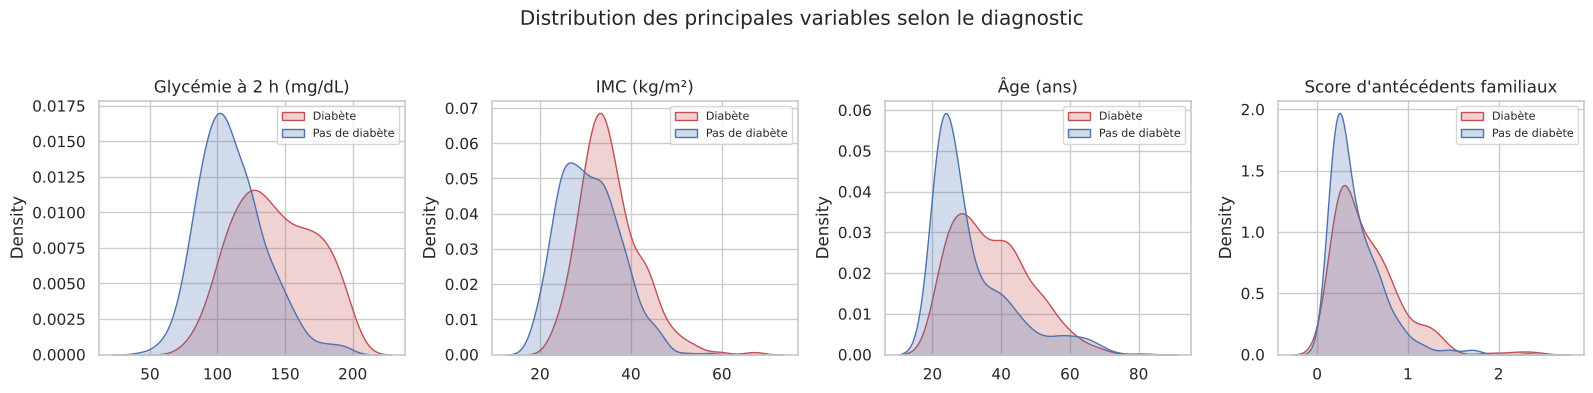

In [4]:
variables = ["glucose", "imc", "age", "antecedents_familiaux"]
titres = ["Glycémie à 2 h (mg/dL)", "IMC (kg/m²)", "Âge (ans)", "Score d'antécédents familiaux"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, v, t in zip(axes, variables, titres):
    sns.kdeplot(data=df, x=v, hue="diabete", fill=True, common_norm=False,
                palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax, warn_singular=False)
    ax.set_title(t); ax.set_xlabel("")
    ax.legend(["Diabète", "Pas de diabète"], fontsize=8)
plt.suptitle("Distribution des principales variables selon le diagnostic", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "exploration.png", dpi=120, bbox_inches="tight"); plt.show()

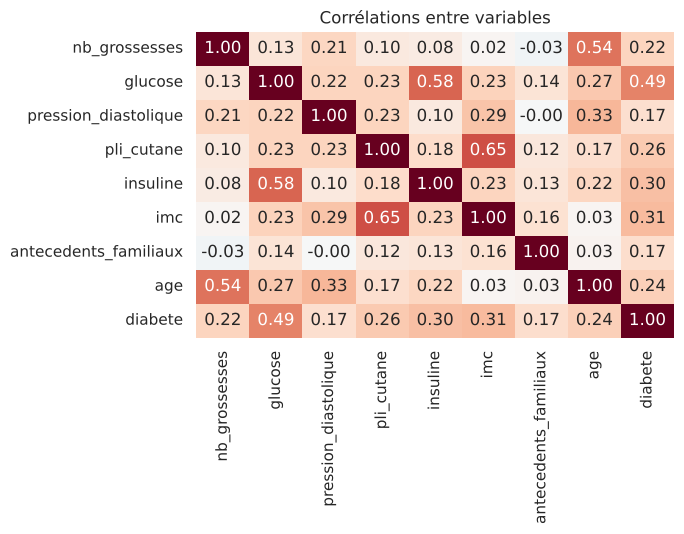

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar=False)
ax.set_title("Corrélations entre variables")
plt.tight_layout(); plt.savefig(FIG / "correlations.png", dpi=120); plt.show()

**À retenir** : la **glycémie** sépare nettement les deux groupes, suivie de l'IMC et de l'âge. Le pli cutané est très corrélé à l'IMC, et l'insuline à la glycémie : ces variables apportent peu d'information en plus.

## 3. Découpage et référence clinique

On met de côté **20 % des patientes** (jeu de test) qu'on ne regardera qu'à la toute fin.

Référence à battre : une **règle clinique simple**, « glycémie à 2 h ≥ 140 mg/dL » (seuil de l'intolérance au glucose selon l'OMS).

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=M.SEED)
print(f"Entraînement : {len(X_train)} patientes | Test : {len(X_test)} patientes")

regle = (X_test["glucose"].fillna(X_train["glucose"].median()) >= 140).astype(float).values
ref = M.metriques(y_test, regle, 0.5)
print(f"Règle glycémie >= 140 : sensibilité {ref['sensibilité']:.0%}, spécificité {ref['spécificité']:.0%}")

Entraînement : 614 patientes | Test : 154 patientes
Règle glycémie >= 140 : sensibilité 46%, spécificité 84%


La règle est très spécifique mais rate **près de la moitié des malades** : insuffisant pour un dépistage. Le machine learning doit faire mieux en combinant toutes les mesures.

## 4. Comparaison des modèles (validation croisée répétée)

Avec 614 patientes, un seul découpage train/validation donnerait des scores très instables. On répète donc 5 fois une validation croisée à 5 plis (25 entraînements par modèle). L'imputation par la médiane est faite **dans** chaque pli pour éviter toute fuite d'information.

In [7]:
modeles = M.construire_modeles()
comparaison = M.comparer_modeles(modeles, X_train, y_train)
comparaison.to_csv(RES / "comparaison_validation.csv", index=False)
comparaison

,modèle,AUC,AUC écart-type,PR-AUC
0,Régression logistique,0.843,0.029,0.740
1,Forêt aléatoire,0.834,0.034,0.723
2,XGBoost,0.821,0.036,0.710


**Résultat honnête** : la **régression logistique fait au moins aussi bien** que les modèles d'arbres, avec un écart-type plus faible. Sur un petit jeu tabulaire où les relations sont presque linéaires (plus la glycémie est haute, plus le risque monte), un modèle simple suffit.

En santé, c'est une bonne nouvelle : un modèle **simple et interprétable** est plus facile à faire valider par des médecins. On retient la régression logistique, et on garde XGBoost comme point de comparaison.

## 5. Choisir le seuil de dépistage

Par défaut, un modèle classe « malade » au-dessus de 0,5. En dépistage, ce n'est pas le bon choix : on préfère envoyer trop de patientes faire un test de confirmation (HbA1c) plutôt que d'en rater.

On cherche le seuil qui garantit **au moins 85 % de sensibilité**, en le calculant sur les prédictions hors plis du jeu d'entraînement (le jeu de test reste intact).

Seuil retenu : 0.359


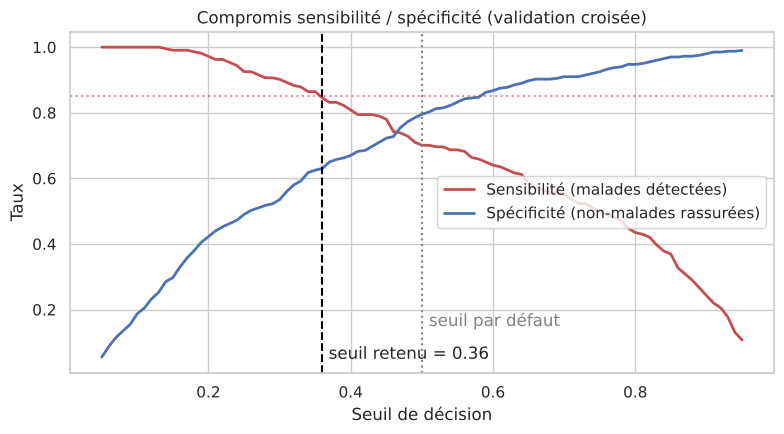

In [8]:
retenu = "Régression logistique"
proba_oof = M.probas_hors_plis(modeles[retenu], X_train, y_train)
seuil = M.seuil_pour_sensibilite(y_train, proba_oof, 0.85)
print(f"Seuil retenu : {seuil:.3f}")

grille = np.linspace(0.05, 0.95, 91)
sens = [(proba_oof[y_train == 1] >= s).mean() for s in grille]
spec = [(proba_oof[y_train == 0] < s).mean() for s in grille]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grille, sens, label="Sensibilité (malades détectées)", color="#C44E52", lw=2)
ax.plot(grille, spec, label="Spécificité (non-malades rassurées)", color="#4C72B0", lw=2)
ax.axvline(seuil, ls="--", color="black"); ax.axvline(0.5, ls=":", color="grey")
ax.text(seuil + 0.01, 0.05, f"seuil retenu = {seuil:.2f}"); ax.text(0.51, 0.15, "seuil par défaut", color="grey")
ax.axhline(0.85, ls=":", color="#C44E52", alpha=.6)
ax.set_xlabel("Seuil de décision"); ax.set_ylabel("Taux"); ax.legend(loc="center right")
ax.set_title("Compromis sensibilité / spécificité (validation croisée)")
plt.tight_layout(); plt.savefig(FIG / "choix_seuil.png", dpi=120); plt.show()

## 6. Évaluation finale sur le jeu de test

In [9]:
lignes, probas_test = [], {}
for nom, m in modeles.items():
    p_oof = proba_oof if nom == retenu else M.probas_hors_plis(m, X_train, y_train)
    s = M.seuil_pour_sensibilite(y_train, p_oof, 0.85)
    m.fit(X_train, y_train)
    probas_test[nom] = m.predict_proba(X_test)[:, 1]
    lignes.append({"modèle": nom, "seuil": s, **M.metriques(y_test, probas_test[nom], s)})
lignes.append({"modèle": "Règle glycémie ≥ 140", "seuil": np.nan, **ref})
resultats = pd.DataFrame(lignes)
resultats.to_csv(RES / "resultats_test.csv", index=False)
resultats[["modèle", "seuil", "AUC", "sensibilité", "spécificité", "VPP", "VPN", "faux négatifs", "patientes orientées"]]

,modèle,seuil,AUC,sensibilité,spécificité,VPP,VPN,faux négatifs,patientes orientées
0,Régression logistique,0.359,0.813,0.870,0.650,0.573,0.903,7,0.532
1,Forêt aléatoire,0.407,0.822,0.852,0.660,0.575,0.892,8,0.519
2,XGBoost,0.308,0.823,0.870,0.660,0.580,0.904,7,0.526
3,Règle glycémie ≥ 140,NaN,0.651,0.463,0.840,0.610,0.743,29,0.266


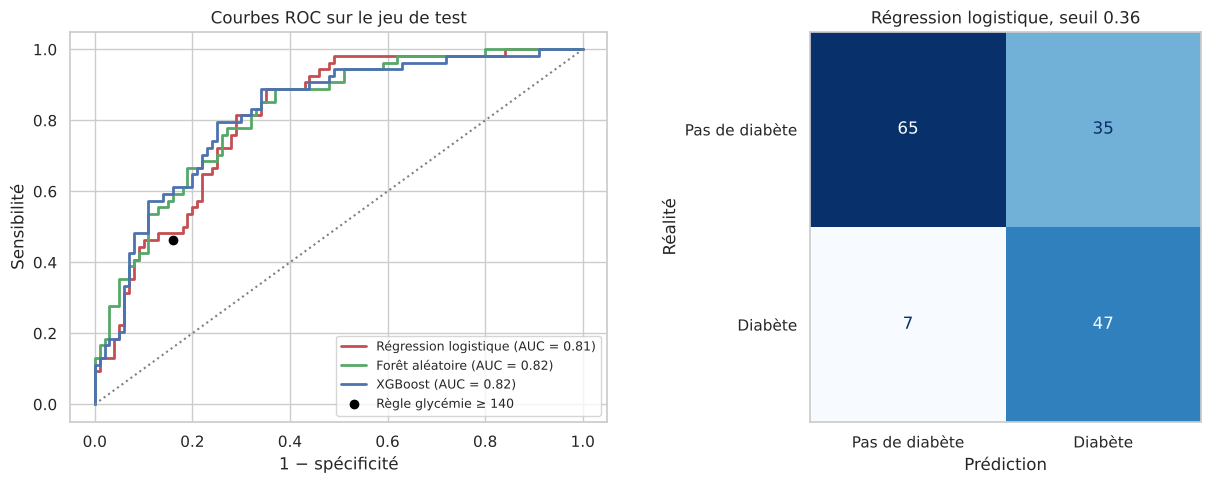

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
couleurs = {"Régression logistique": "#C44E52", "Forêt aléatoire": "#55A868", "XGBoost": "#4C72B0"}
for nom, p in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = resultats.set_index("modèle").loc[nom, "AUC"]
    axes[0].plot(fpr, tpr, label=f"{nom} (AUC = {auc:.2f})", color=couleurs[nom], lw=2)
axes[0].scatter(1 - ref["spécificité"], ref["sensibilité"], color="black", zorder=5,
                label="Règle glycémie ≥ 140")
axes[0].plot([0, 1], [0, 1], ls=":", color="grey")
axes[0].set_xlabel("1 − spécificité"); axes[0].set_ylabel("Sensibilité")
axes[0].set_title("Courbes ROC sur le jeu de test"); axes[0].legend(fontsize=9)

ConfusionMatrixDisplay.from_predictions(
    y_test, (probas_test[retenu] >= seuil).astype(int),
    display_labels=["Pas de diabète", "Diabète"], cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_xlabel("Prédiction"); axes[1].set_ylabel("Réalité"); axes[1].grid(False)
axes[1].set_title(f"Régression logistique, seuil {seuil:.2f}")
plt.tight_layout(); plt.savefig(FIG / "roc_confusion.png", dpi=120); plt.show()

**Lecture** : avec le seuil de dépistage, le modèle détecte **87 % des malades** du jeu de test (47 sur 54), contre 46 % pour la règle glycémie seule. Sur le test, les trois modèles sont au coude-à-coude : l'écart d'AUC (0,81 contre 0,82) est bien plus petit que la variabilité mesurée en validation croisée. La contrepartie : environ une patiente sur deux est orientée vers un test de confirmation. La VPN élevée signifie qu'une patiente classée « à faible risque » a de bonnes chances de l'être vraiment.

## 7. Les probabilités sont-elles fiables ? (calibration)

Un médecin lira « 30 % de risque ». Il faut que, parmi les patientes à qui on annonce 30 %, environ 30 % soient réellement malades.

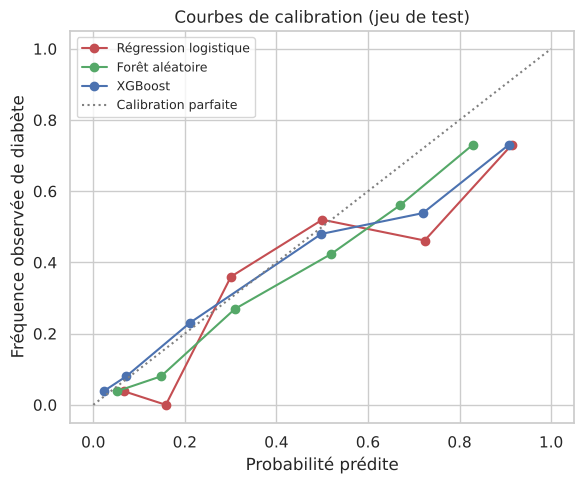

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
for nom, p in probas_test.items():
    frac, moy = calibration_curve(y_test, p, n_bins=6, strategy="quantile")
    ax.plot(moy, frac, marker="o", label=nom, color=couleurs[nom])
ax.plot([0, 1], [0, 1], ls=":", color="grey", label="Calibration parfaite")
ax.set_xlabel("Probabilité prédite"); ax.set_ylabel("Fréquence observée de diabète")
ax.set_title("Courbes de calibration (jeu de test)"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "calibration.png", dpi=120); plt.show()

Les modèles avec `class_weight="balanced"` **surestiment** le risque : c'est voulu, le rééquilibrage pousse les probabilités vers le haut pour mieux détecter les malades. Le classement reste bon, mais pour **annoncer** une probabilité à une patiente, il faudrait recalibrer (méthode de Platt ou isotonique). C'est noté dans les pistes d'amélioration.

## 8. Expliquer les prédictions (SHAP)

### Vue globale : quelles variables comptent ?

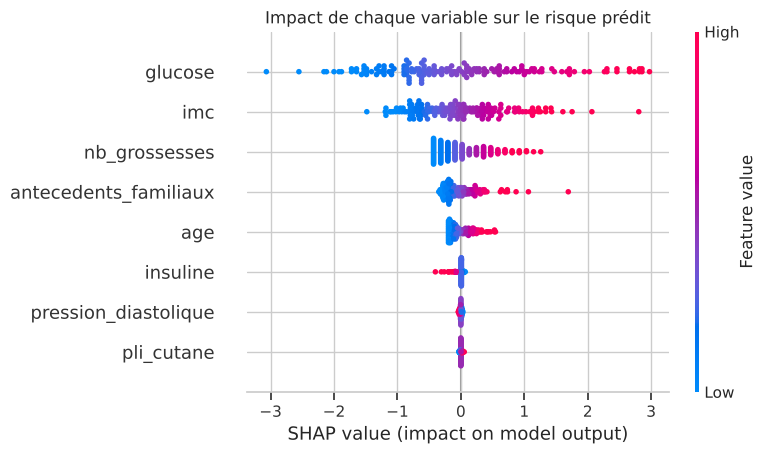

In [12]:
pipe = modeles[retenu]
pretraitement = pipe[:-1]
X_train_t = pd.DataFrame(pretraitement.transform(X_train), columns=X.columns)
X_test_t = pd.DataFrame(pretraitement.transform(X_test), columns=X.columns)

explainer = shap.LinearExplainer(pipe[-1], shap.maskers.Independent(X_train_t, max_samples=len(X_train_t)))
sv = explainer(X_test_t)
sv.data = X_test.fillna(X_train.median()).values   # valeurs d'origine pour l'affichage

shap.plots.beeswarm(sv, show=False, max_display=8)
plt.title("Impact de chaque variable sur le risque prédit")
plt.tight_layout(); plt.savefig(FIG / "shap_global.png", dpi=120, bbox_inches="tight"); plt.show()

In [13]:
coef = pd.Series(pipe[-1].coef_[0], index=X.columns)
odds = np.exp(coef).sort_values(ascending=False).to_frame("odds ratio (+1 écart-type)")
odds

,odds ratio (+1 écart-type)
glucose,3.266
imc,2.033
nb_grossesses,1.452
antecedents_familiaux,1.333
age,1.205
pli_cutane,1.014
pression_diastolique,0.985
insuline,0.956


**Interprétation médicale** : une glycémie plus élevée d'un écart-type (≈ 30 mg/dL) multiplie le risque (en odds) par environ 3. Viennent ensuite l'IMC (×2), le nombre de grossesses et les antécédents familiaux. Une fois ces variables prises en compte, la tension, le pli cutané et l'insuline n'apportent presque rien. Ces résultats sont **cohérents avec la littérature médicale**, ce qui renforce la confiance dans le modèle.

### Vue individuelle : pourquoi cette patiente est-elle signalée ?

Les mesures manquantes de la patiente sont affichées avec la valeur médiane utilisée par le modèle.

Patiente n°300 : risque prédit 80%, diabète réel : oui
nb_grossesses             0.000
glucose                 167.000
pression_diastolique        NaN
pli_cutane                  NaN
insuline                    NaN
imc                      32.300
antecedents_familiaux     0.839
age                      30.000


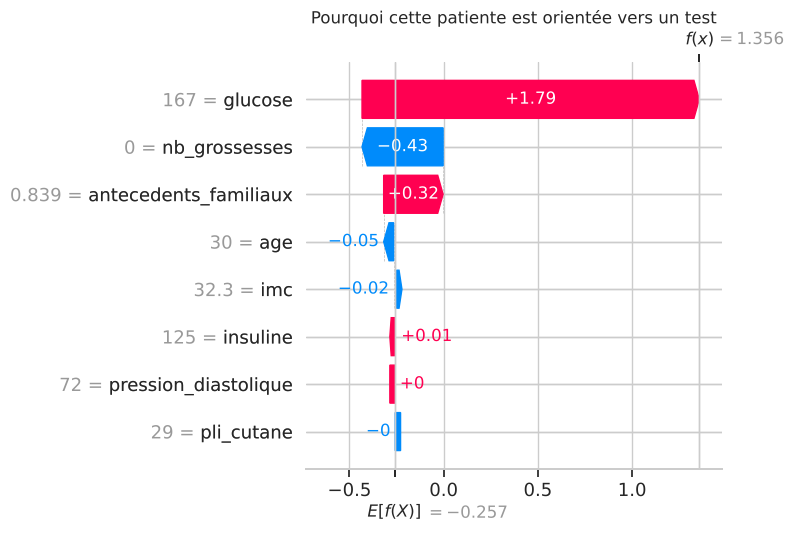

In [14]:
p = probas_test[retenu]
signalees = np.where((p >= seuil) & (y_test.values == 1))[0]
i = signalees[np.argsort(p[signalees])[len(signalees) // 2]]   # cas typique, ni extrême ni limite
print(f"Patiente n°{X_test.index[i]} : risque prédit {p[i]:.0%}, diabète réel : {'oui' if y_test.iloc[i] else 'non'}")
print(X_test.iloc[i].to_string())

shap.plots.waterfall(sv[i], show=False, max_display=8)
plt.title("Pourquoi cette patiente est orientée vers un test")
plt.tight_layout(); plt.savefig(FIG / "shap_patiente.png", dpi=120, bbox_inches="tight"); plt.show()

## 9. Conclusion

- Un modèle simple (**régression logistique**) atteint une AUC d'environ **0,81 à 0,84** et fait aussi bien que XGBoost sur ce jeu.
- Avec un seuil adapté au dépistage, il détecte environ **85 % des malades**, bien plus que la règle clinique « glycémie ≥ 140 ».
- Les variables clés (glycémie, IMC, hérédité, âge) correspondent aux facteurs de risque connus.

**Limites** : 768 patientes d'une seule population (femmes pima, Arizona, années 1980-90) : le modèle ne se généralise pas tel quel à d'autres populations. Beaucoup de dosages d'insuline manquent. Les probabilités doivent être recalibrées avant d'être communiquées.

**Pistes** : recalibration (isotonique), validation externe sur une autre cohorte (ex. NHANES), audit d'équité par tranche d'âge, application Streamlit pour les soignants.